In [298]:
include("CW1.jl")

duffing_oscillator (generic function with 1 method)

In [299]:
import Pkg

Pkg.activate(dirname(@__DIR__))
Pkg.add(["DynamicalSystems", "CairoMakie"])
Pkg.status(["DynamicalSystems", "CairoMakie"]; mode = Pkg.PKGMODE_MANIFEST)
Pkg.instantiate()
Base.active_project()

"c:\\Users\\stant\\OneDrive - University of Exeter\\Documents\\Maths\\Project.toml"

In [300]:
using DynamicalSystems
using CairoMakie
using Statistics
using LinearAlgebra

## Question 1

### 1.3

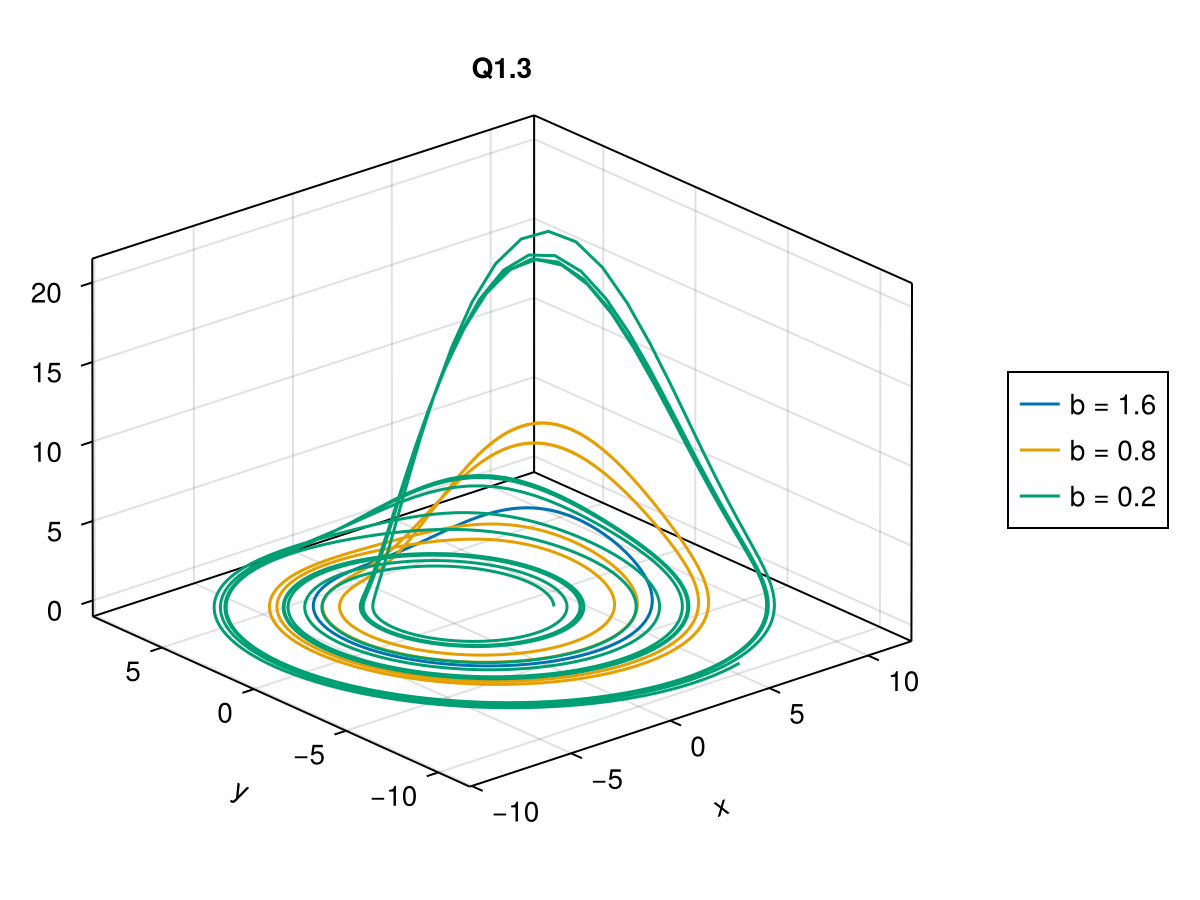

CairoMakie.Screen{IMAGE}


In [301]:
b_vals = [1.6, 0.8, 0.2]
colours = ["red", "green", "blue"]
graphs = []

fig = Figure()
ax = Axis3(fig[1, 1]; title = "Q1.3")

for b in b_vals
    p0 = [0.2, b, 5.7]
    u0 = [5.2, 0, 0]
    q1vals = CoupledODEs(q1, u0, p0)
    total_time = 100
    X, t = trajectory(q1vals, total_time; Ttr = 1000, Δt = 0.05)
    graph = lines!(ax, X)
    push!(graphs, graph)
end

Legend(fig[1, 2], graphs, ["b = 1.6", "b = 0.8", "b = 0.2"])
display(fig)

### 1.4

In [302]:
mean_x_vals = []
mean_z_vals = []
b_values = []
for b in 0.2:0.01:1.6
    p0 = [0.2, b, 5.7]
    u0 = [5.2, 0, 0]
    q1_4vals = CoupledODEs(q1, u0, p0)
    total_time = 1_000
    X, t = trajectory(q1_4vals, total_time; Ttr = 0000)
    x_vals, _, z_vals = columns(X)
    mean_x = mean(x_vals)
    mean_z = mean(z_vals)
    push!(mean_x_vals, mean_x)
    push!(mean_z_vals, mean_z)
    push!(b_values, b)
end



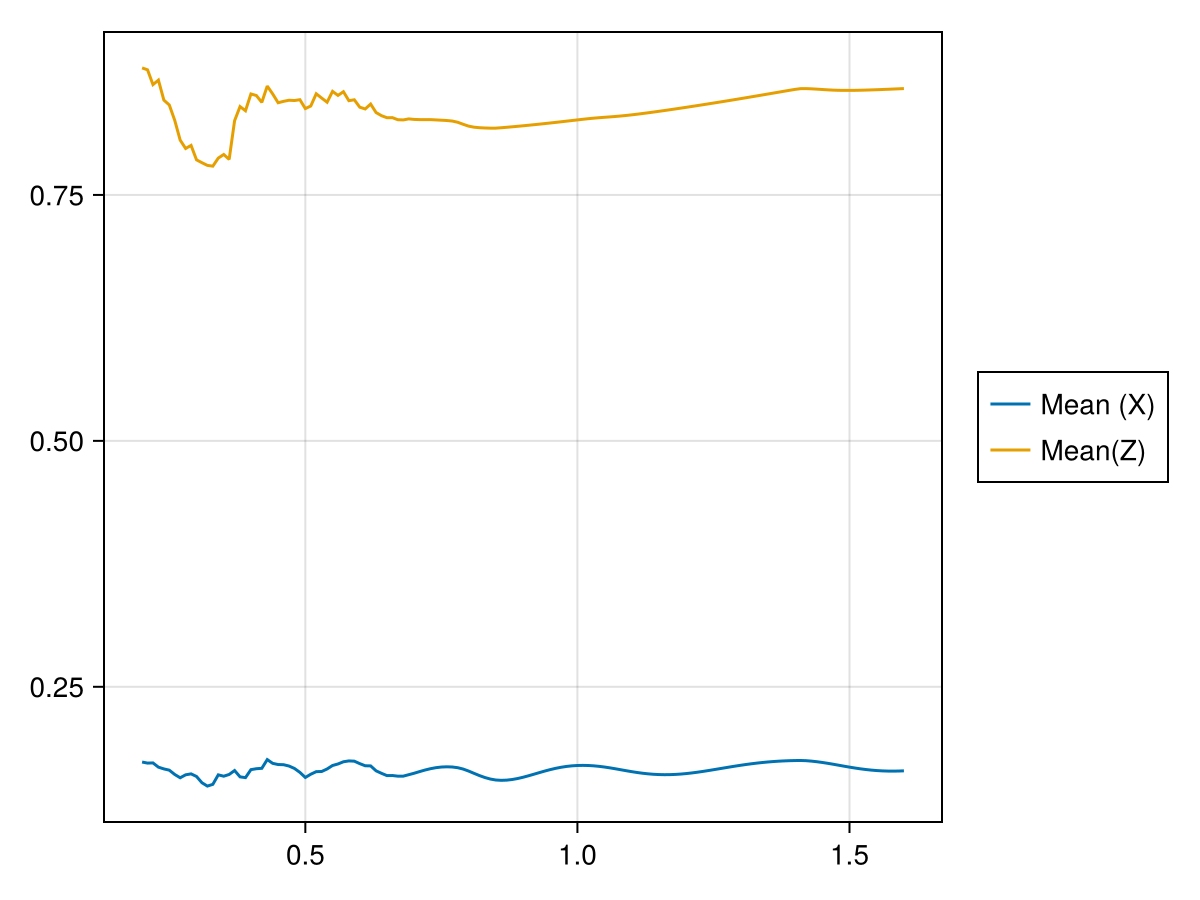

In [303]:
fig = Figure()
ax = Axis(fig[1,1])
x_graph = lines!(ax, b_values, mean_x_vals)
z_graph = lines!(ax, b_values, mean_z_vals)
Legend(fig[1, 2], [x_graph, z_graph], ["Mean (X)", "Mean(Z)"])
fig

In [304]:
display("text/markdown", Base.doc(poincaresos))

```julia
poincaresos(A::AbstractStateSpaceSet, plane; kwargs...) → P::StateSpaceSet
```

Calculate the Poincaré surface of section of the given dataset with the given `plane` by performing linear interpolation betweeen points that sandwich the hyperplane.

Argument `plane` and keywords `direction, warning, save_idxs` are the same as in [`PoincareMap`](@ref).

```julia
poincaresos(ds::CoupledODEs, plane, T = 1000.0; kwargs...) → P::StateSpaceSet
```

Return the iterations of `ds` on the Poincaré surface of section with the `plane`, by evolving `ds` up to a total of `T`. Return a [`StateSpaceSet`](@ref) of the points that are on the surface of section.

This function initializes a [`PoincareMap`](@ref) and steps it until its [`current_crossing_time`](@ref) exceeds `T`. You can also use [`trajectory`](@ref) with [`PoincareMap`](@ref) to get a sequence of `N::Int` points instead.

The keywords `Ttr, save_idxs` act as in [`trajectory`](@ref). See [`PoincareMap`](@ref) for `plane` and all other keywords.


In [305]:
display("text/markdown", Base.doc(PoincareMap))

```julia
PoincareMap <: DiscreteTimeDynamicalSystem
PoincareMap(ds::CoupledODEs, plane; kwargs...) → pmap
```

A discrete time dynamical system that produces iterations over the Poincaré map[^DatserisParlitz2022] of the given continuous time `ds`. This map is defined as the sequence of points on the Poincaré surface of section, which is defined by the `plane` argument.

Iterating `pmap` also mutates `ds` which is referenced in `pmap`.

See also [`StroboscopicMap`](@ref), [`poincaresos`](@ref).

## Keyword arguments

  * `direction = -1`: Only crossings with `sign(direction)` are considered to belong to the surface of section. Negative direction means going from less than $b$ to greater than $b$.
  * `u0 = nothing`: Specify an initial state. If `nothing` it is the `current_state(ds)`.
  * `rootkw = (xrtol = 1e-6, atol = 1e-8)`: A `NamedTuple` of keyword arguments passed to `find_zero` from [Roots.jl](https://github.com/JuliaMath/Roots.jl).
  * `Tmax = 1e3`: The argument `Tmax` exists so that the integrator can terminate instead of being evolved for infinite time, to avoid cases where iteration would continue forever for ill-defined hyperplanes or for convergence to fixed points, where the trajectory would never cross again the hyperplane. If during one `step!` the system has been evolved for more than `Tmax`, then `step!(pmap)` will terminate and error.

## Description

The Poincaré surface of section is defined as sequential transversal crossings a trajectory has with any arbitrary manifold, but here the manifold must be a hyperplane. `PoincareMap` iterates over the crossings of the section.

If the state of `ds` is $\mathbf{u} = (u_1, \ldots, u_D)$ then the equation defining a hyperplane is

$$
a_1u_1 + \dots + a_Du_D = \mathbf{a}\cdot\mathbf{u}=b
$$

where $\mathbf{a}, b$ are the parameters of the hyperplane.

In code, `plane` can be either:

  * A `Tuple{Int, <: Real}`, like `(j, r)`: the plane is defined as when the `j`th variable of the system equals the value `r`.
  * A vector of length `D+1`. The first `D` elements of the vector correspond to $\mathbf{a}$ while the last element is $b$.

`PoincareMap` uses `ds`, higher order interpolation from DifferentialEquations.jl, and root finding from Roots.jl, to create a high accuracy estimate of the section.

`PoincareMap` follows the [`DynamicalSystem`](@ref) interface with the following adjustments:

1. `dimension(pmap) == dimension(ds)`, even though the Poincaré map is effectively 1 dimension less.
2. Like [`StroboscopicMap`](@ref) time is discrete and counts the iterations on the surface of section. [`initial_time`](@ref) is always `0` and [`current_time`](@ref) is current iteration number.
3. A new function [`current_crossing_time`](@ref) returns the real time corresponding to the latest crossing of the hyperplane. The corresponding state on the hyperplane is `current_state(pmap)` as expected.
4. For the special case of `plane` being a `Tuple{Int, <:Real}`, a special `reinit!` method is allowed with input state of length `D-1` instead of `D`, i.e., a reduced state already on the hyperplane that is then converted into the `D` dimensional state.
5. The `initial_state(pmap)` returns the state initial state of the map. This is not `u0` because `u0` is evolved forwards until it resides on the Poincaré plane.
6. In the `reinit!` function, the `t0` keyword denotes the starting time of the continuous time dynamical system, as the starting time of the `PoincareMap` is by definition always 0.

## Example

```julia
using DynamicalSystemsBase, PredefinedDynamicalSystems
ds = Systems.rikitake(zeros(3); μ = 0.47, α = 1.0)
pmap = poincaremap(ds, (3, 0.0))
step!(pmap)
next_state_on_psos = current_state(pmap)
```

[^DatserisParlitz2022]: Datseris & Parlitz 2022, *Nonlinear Dynamics: A Concise Introduction Interlaced with Code*, [Springer Nature, Undergrad. Lect. Notes In Physics](https://doi.org/10.1007/978-3-030-91032-7)


In [306]:
display("text/markdown", Base.doc(current_crossing_time))

```julia
current_crossing_time(pmap::PoincareMap) → tcross
```

Return the time of the latest crossing of the Poincare section.


In [307]:
# set_parameter!(q1_4vals, 2, 0.2) # Set 2nd param (b) to 0.2
# current_parameters(q1_4vals)
# u0 = [5.2, 0, 0]

## 1.6 - Remove Poincaresos

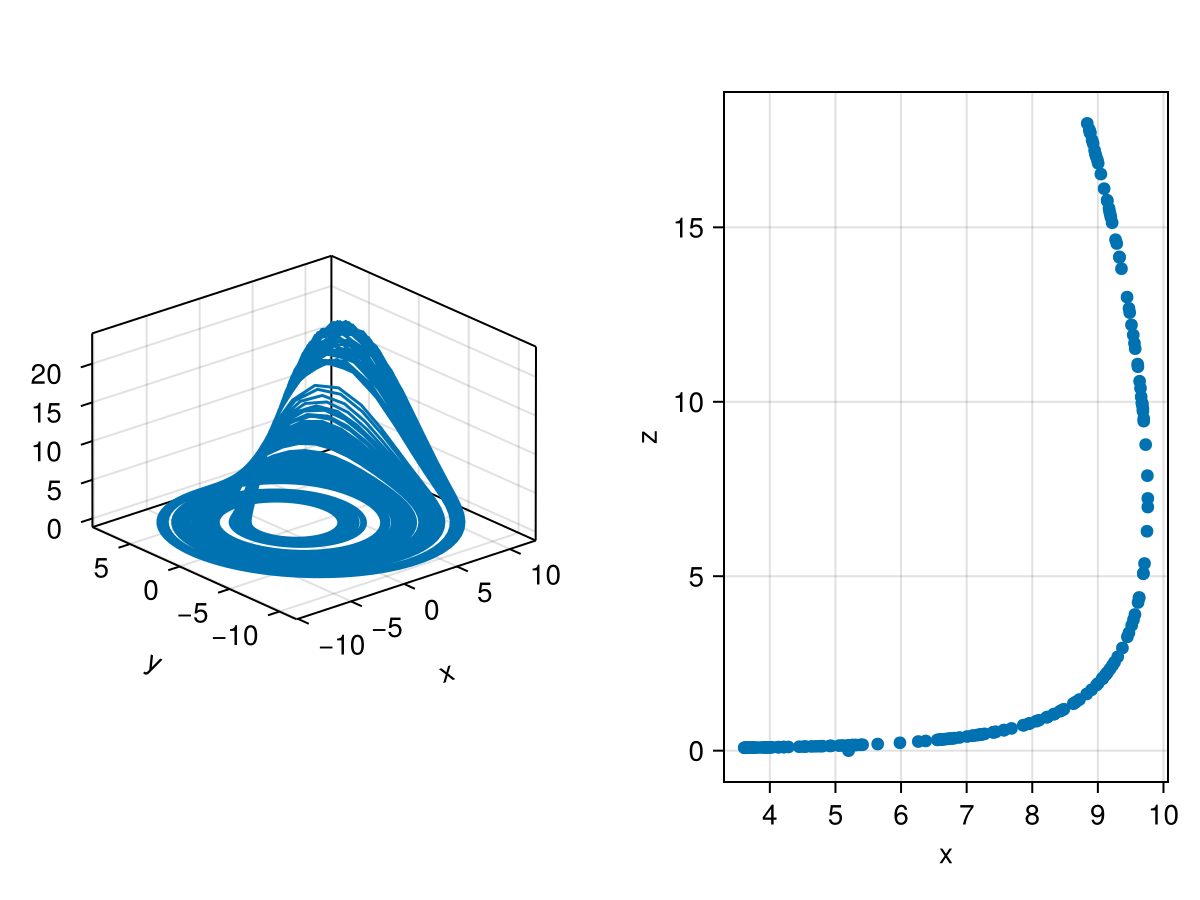

In [308]:
A = CoupledODEs(q1, [5.2, 0, 0], [0.2, 0.2, 5.7])
poincare_map = psos1(A, 2, 0.0)
fig = Figure()
ax = Axis3(fig[1, 1])
X, t = trajectory(A, 1000)
lines!(ax, X)
ax = Axis(fig[1, 2], xlabel = "x", ylabel="z")
scatter!(ax, poincare_map[:, 1], poincare_map[:, 3])
fig

## 1.7 - Remove Poincaremap

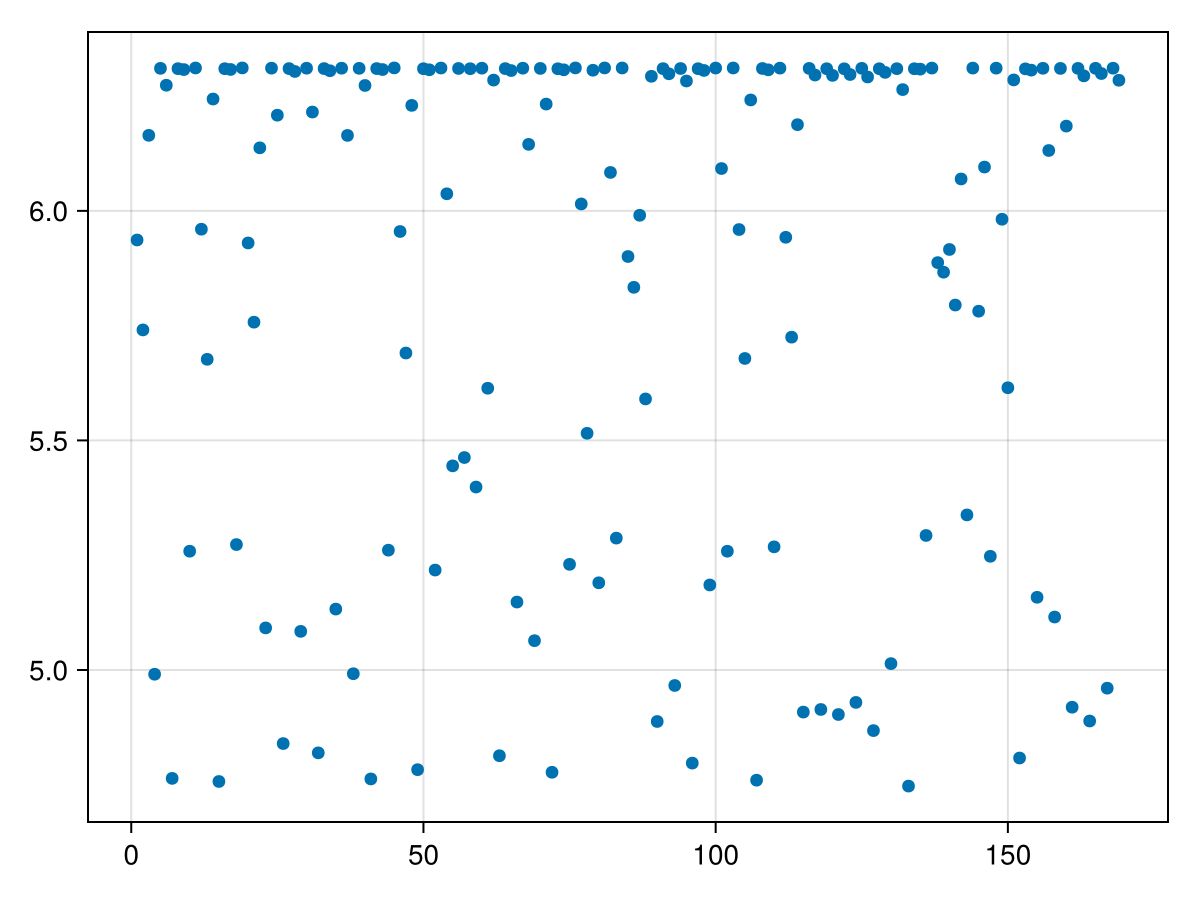

In [309]:
A = CoupledODEs(q1, [5.2, 0, 0], [0.2, 0.2, 5.7])
absolute_times = (psos2(A, t, 2, 0.0))
# step!(p_map)
# current_crossing_time(p_map)
return_times = diff(absolute_times)
scatter(return_times)

## 1.8

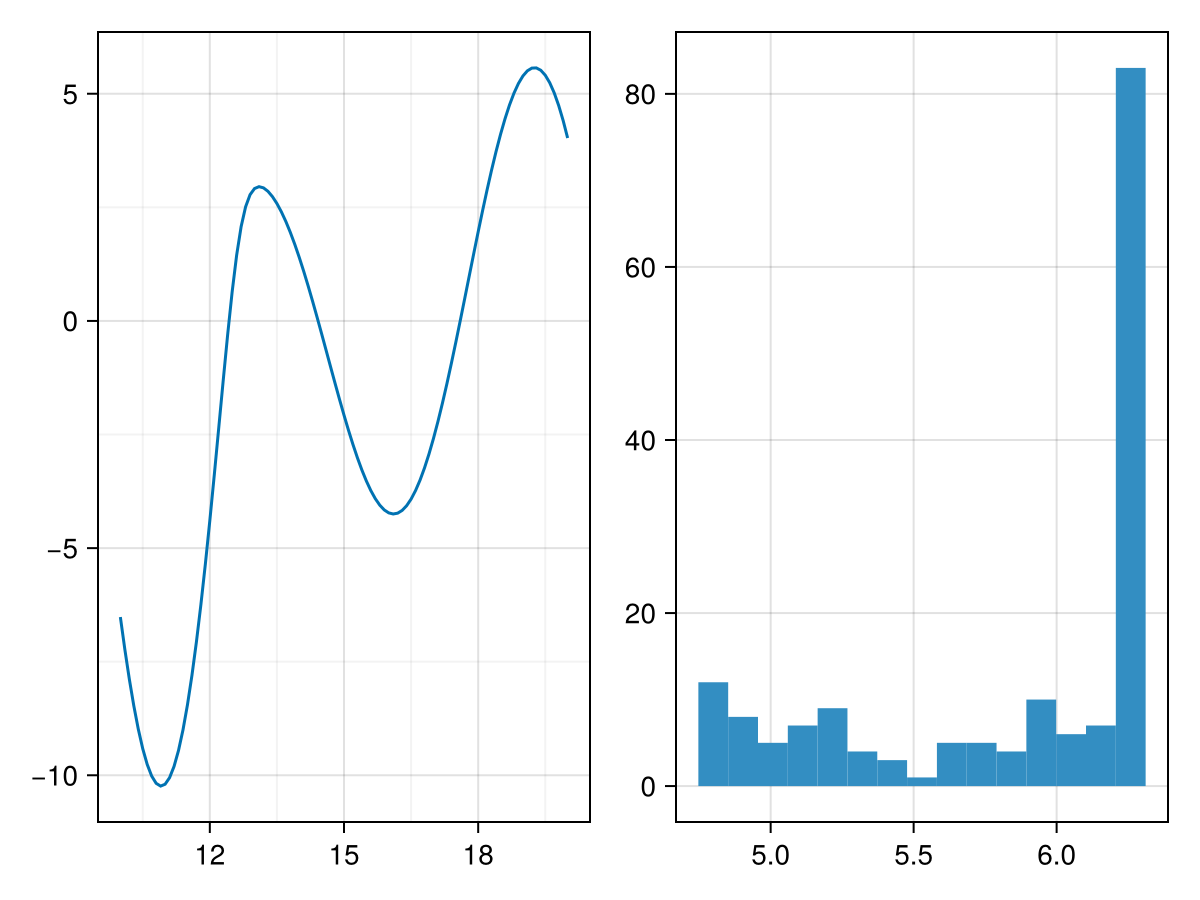

In [310]:
X, t = trajectory(A, 10 ;Ttr = 10) # Evaluate the ODE for t in [10, 20]
y_vals = X[:, 2]
fig = Figure()
ax = Axis(fig[1, 1], xminorgridvisible = true, yminorgridvisible=true)
lines!(ax, t, y_vals)
ax = Axis(fig[1, 2])
sorted_return_times = sort(return_times)
median_return_time = sorted_return_times[div(length(sorted_return_times), 2)]
hist!(ax, return_times)
fig

## The period here is roughly 6 seconds, as reflected in the roughly 6 second return time

## 2.1

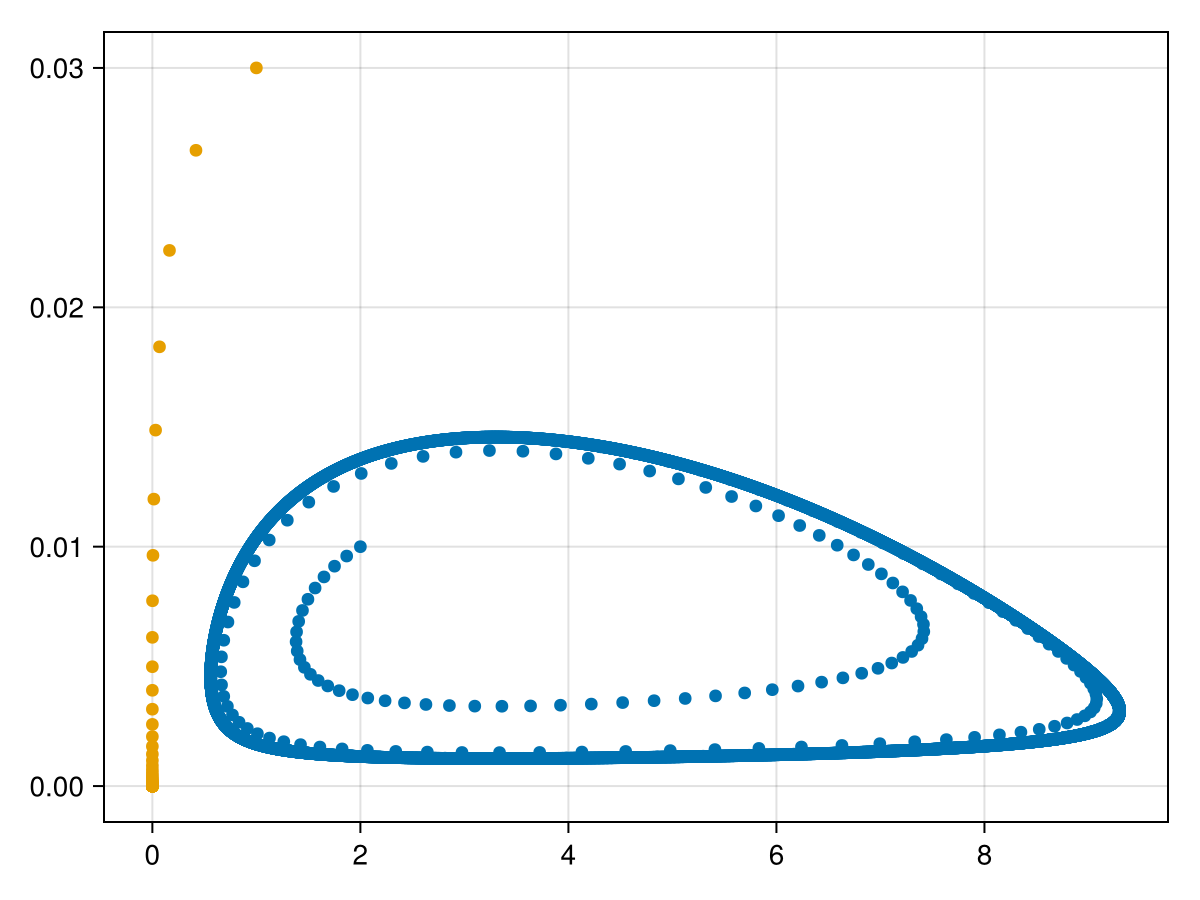

In [311]:
fig = Figure()
ax = Axis(fig[1, 1])
points = [[2, 0.01], [1, 3e-2]]
p0 = [2, 2.2]
total_time = 1000
for u0 in points
    NP_system = CoupledODEs(NP_DS, u0, p0)
    X, t = trajectory(NP_system, total_time)
    scatter!(ax, X)
end
fig

## 2.3

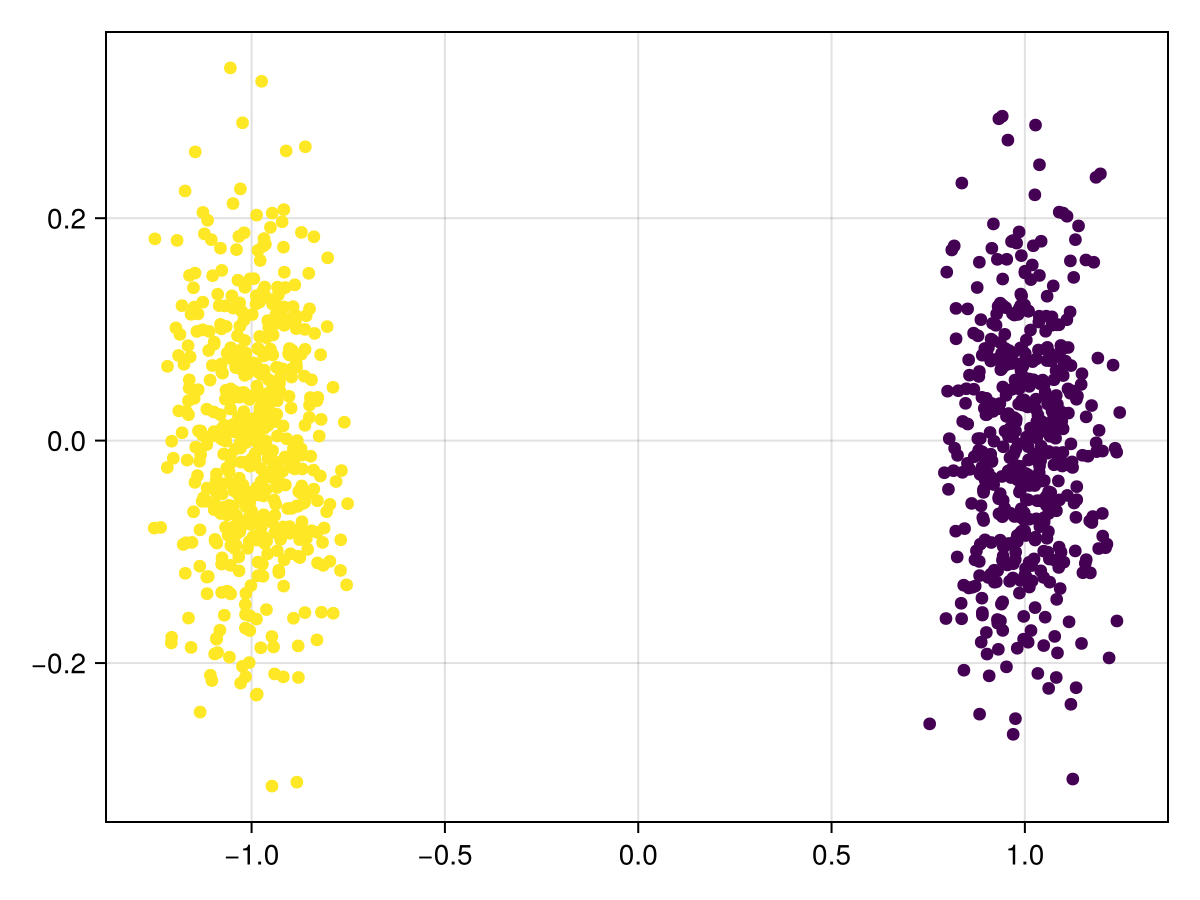

In [312]:
randompoint() = [rand([-1, 1]) + 0.1randn(), 0.1randn()]
features = [randompoint() for _ in 1:1000]

groups = simple_grouping(features, 1.5)

fig = Figure()
ax = Axis(fig[1, 1])
scatter!(ax, first.(features), last.(features); color = groups)
# groups
fig

## 2.3

In [313]:
function featuriser(X)
    N, p = columns(X)
    mean_N = mean(N)
    sd_p = std(p)
    return SVector(mean_N, sd_p)
end

featuriser (generic function with 1 method)

In [314]:
density = 100
Ng = range(0, 15; length = density) .+ 0.01
Pg = range(0, 30e-3; length = density) .+ 1e-6
points = vec([(n, p) for n in Ng, p in Pg])
ds = CoupledODEs(NP_DS, [Ng[1], Pg[1]], [2, 2.2])
groups = fg1(ds, featuriser, 4, points; Ttr = 400, Dt = 0.2, T=40)

10000-element Vector{Int64}:
 1
 2
 2
 2
 2
 2
 2
 2
 2
 2
 ⋮
 1
 1
 1
 1
 1
 1
 1
 1
 1

## Below was a debugging cell to verify the features are grouped correctly, and the featuriser is chosen well

In [315]:
# fig = Figure()
# ax = Axis(fig[1, 1])
# scatter!(ax, features, color=groups)
# fig

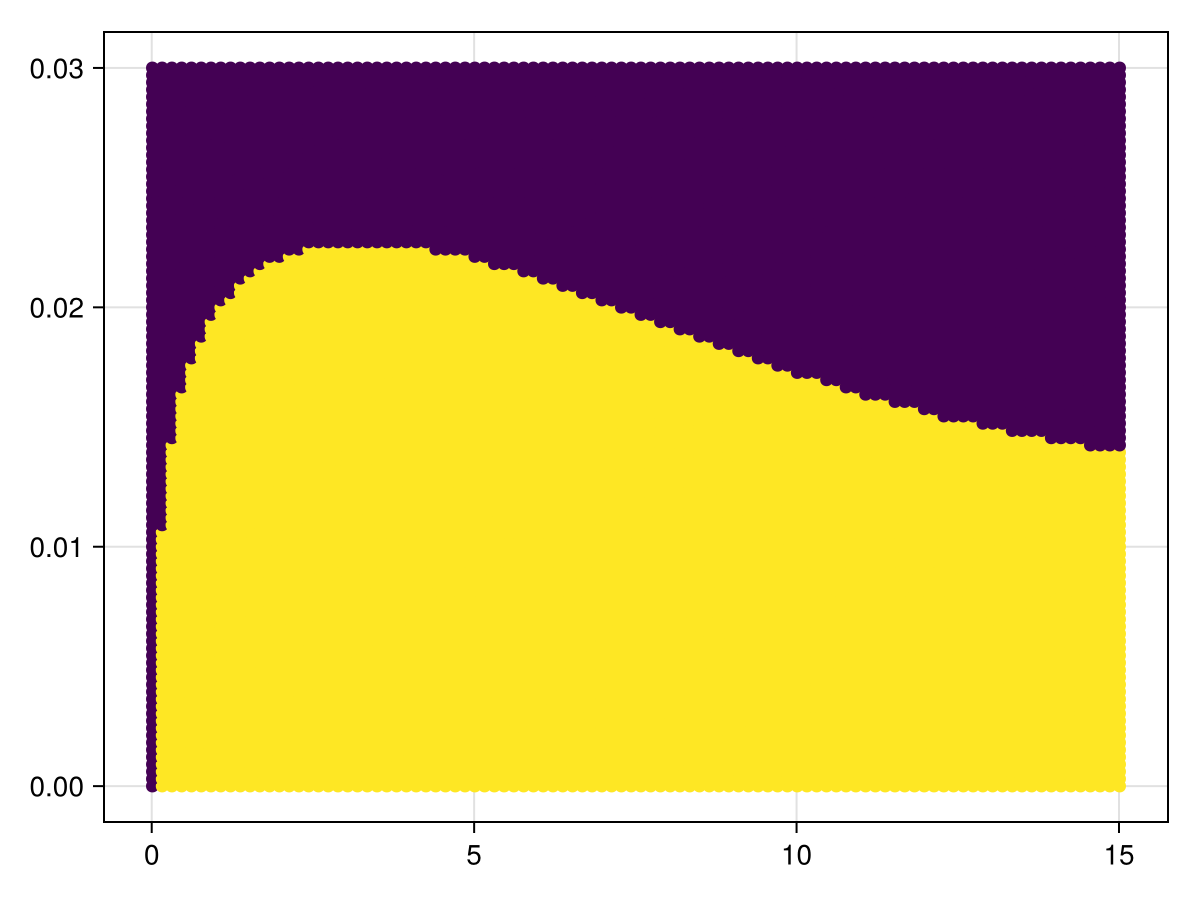

In [316]:
fig = Figure()
ax = Axis(fig[1, 1])
scatter!(ax, points, color=groups)
fig

## 2.4

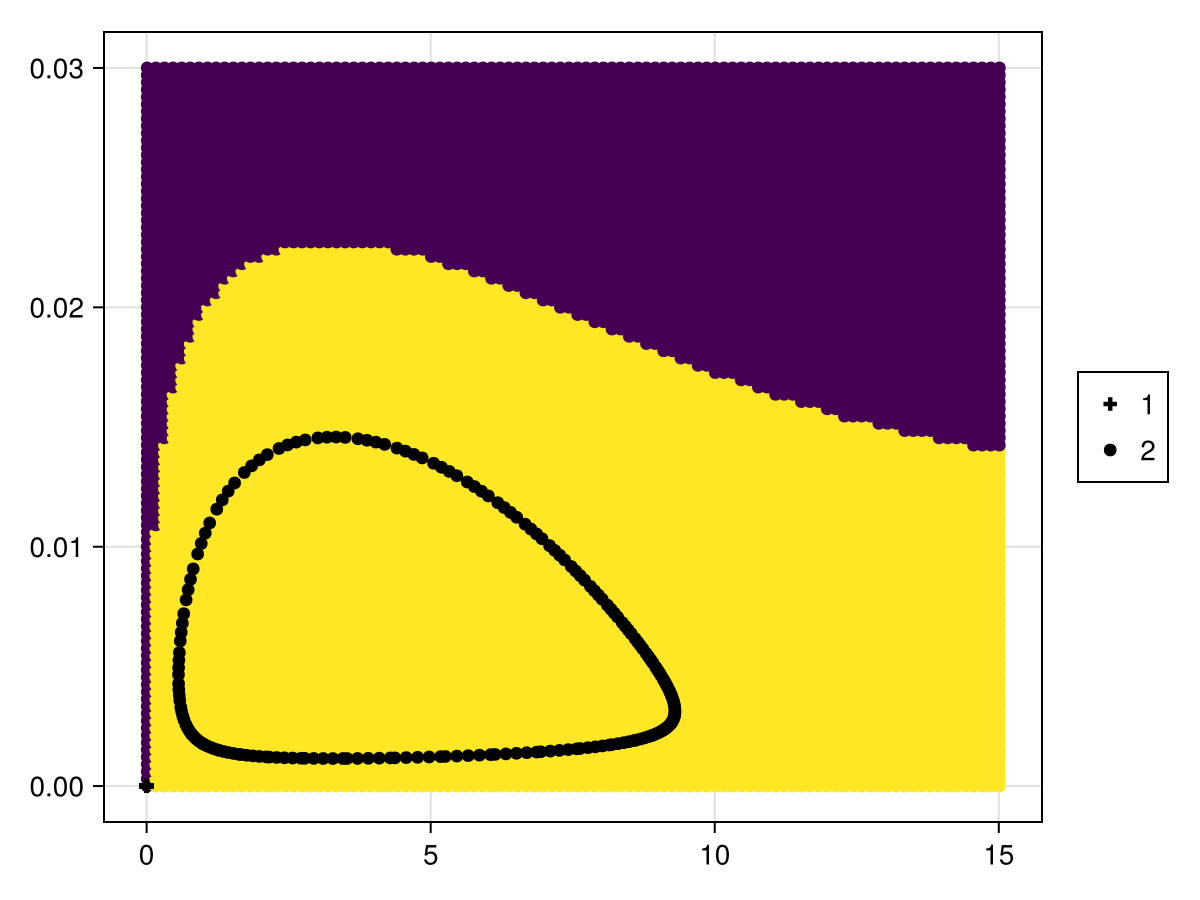

In [317]:
density = 100
Ng = range(0, 15; length = density) .+ 0.01
Pg = range(0, 30e-3; length = density) .+ 1e-6
points = vec([(n, p) for n in Ng, p in Pg])
ds = CoupledODEs(NP_DS, [Ng[1], Pg[1]], [2, 2.2])
groups, group_trajs, boa_fractions = fg2(ds, featuriser, 4, points; Ttr = 400, Dt = 0.2, T=40)
fig = Figure()
ax = Axis(fig[1, 1])
scatter!(ax, points, color=groups)
graphs = []
markers = [:cross, :circle]
for (i, traj) in enumerate(group_trajs)
    push!(graphs, scatter!(ax, traj, color = :black, marker = markers[i]))
end
Legend(fig[1, 2], graphs, ["1", "2"])#boa_fractions
fig

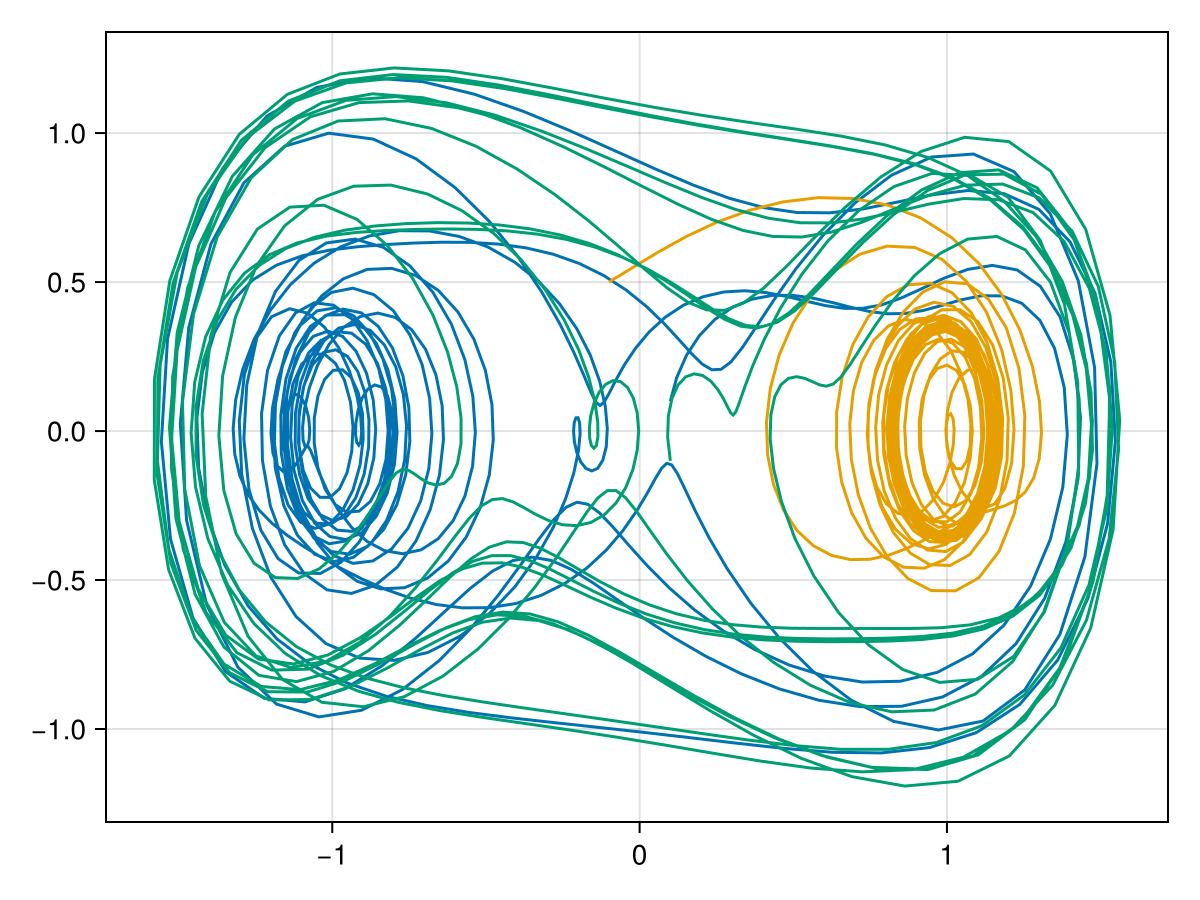

In [318]:
fig = Figure()
ax = Axis(fig[1,1])
δ, f, ω = 0.1, 0.45, 2.15
p = [δ, f, ω]
τ = 2π/ω
u = [0.1, 0.1, 0]
duffing_ds = CoupledODEs(duffing_oscillator, u, p)
∇t = τ/20
points = [[0.1, 0.1, 0], [-0.1, 0.5, 0], [0.1, -0.1, 0]]
for u0 in points
    X, t = trajectory(duffing_ds, 100, u0; Ttr = 0, Dt = ∇t)
    x, v, _ = columns(X)
    lines!(ax, x, v)
end
fig

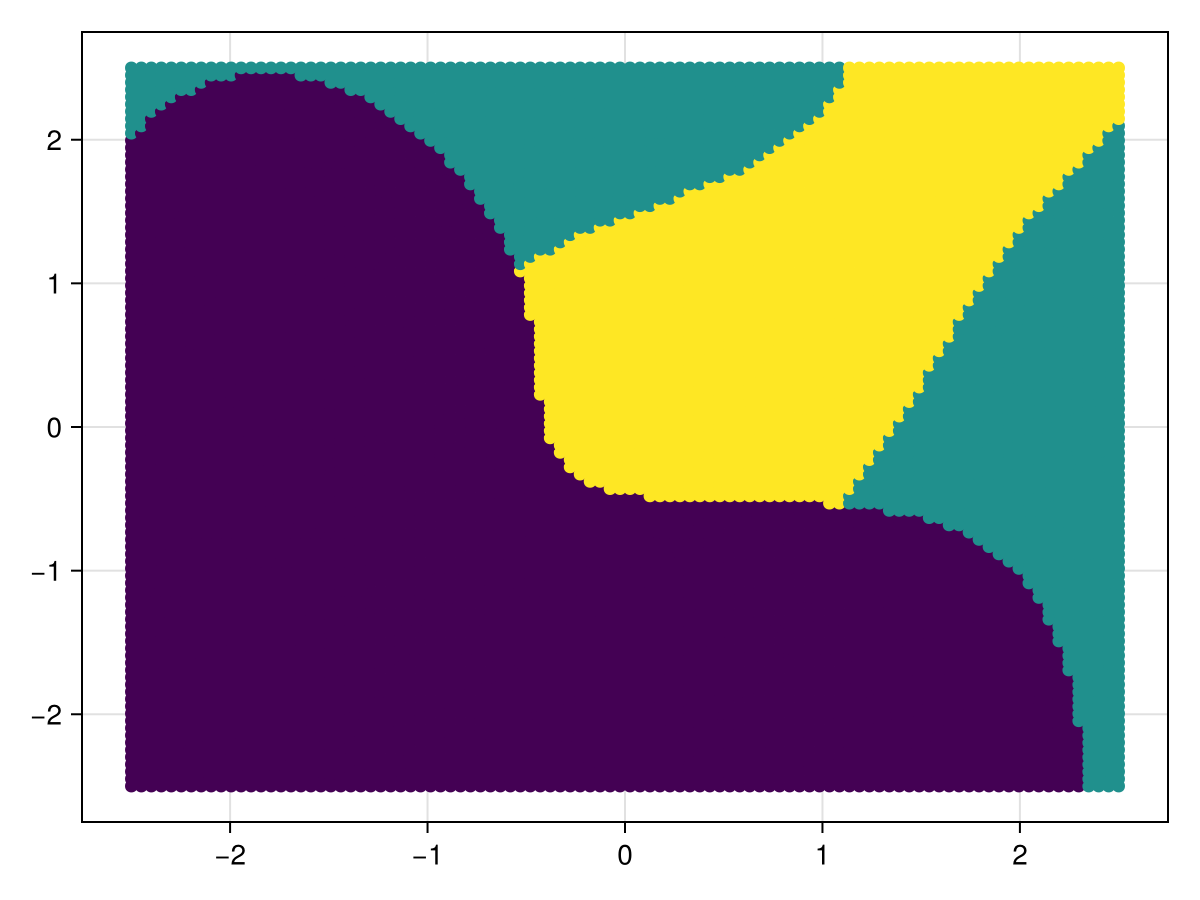

In [ ]:
function duffing_featuriser(X)
    x, v, t = X
    mean_x = mean(x)
    sd_v = std(v)
    return SVector(mean_x, sd_v)
end
density = 100
xg = range(-2.5, 2.5; length = density)
vg = range(-2.5, 2.5; length = density)
duffing_points = vec([(x, v, 0) for x in xg, v in vg])
groups, group_trajs = fg2(duffing_ds, duffing_featuriser, 2, duffing_points; Ttr = 0, Dt = ∇t, T = 100)
fig = Figure()
ax = Axis(fig[1, 1])
scatter!(ax, duffing_points, color=groups)
graphs = []
markers = [:cross, :circle]
# for (i, traj) in enumerate(group_trajs)
#     push!(graphs, scatter!(ax, traj, color = :black, marker = markers[i]))
# end
fig